# Consigne

Avec une augmentation significative du nombre d’étudiants, l’hypothèse de files d’attente infinies devient irréaliste, cf `notebooks/WaterfallNotebook1.ipynb`. On note ks et kf les tailles respectives des files d’exécution et de renvoi de résultats. Si un push tag est refusé, l’étudiant reçoit un message d’erreur. Si le résultat d’un moulinettage est refusé dans la seconde file, l’étudiant reçoit un retour vide. Discutez des proportions de refus selon les paramètres.

# Hypotheses

### File 1 : M/M/K/ks

Un push tag arrive dans le système d'exécution de la test-suite. Ce système a une capacité totale de ks étudiants (serveurs et places d'attente compris). Si le système est plein, le push est refusé et l'étudiant reçoit un message d'erreur. Sinon, le code est placé dans une file d'attente FIFO jusqu'à ce que l'un des K serveurs se libère.

Ainsi, on reprend la file markovienne de la partie 1, avec K serveurs, mais cette fois sa capacité est finie : ks ≥ K. Il y a donc K places en service et ks − K places d'attente. Si ks = K, il n'y a aucune attente (loi d'Erlang-B).

| Notation | Propriété du système réel qu'il représente 
|---|---|
| M (arrivées) | Un grand nombre d'étudiants envoient leurs pushs de façon indépendante, ce qui se modélise par un processus de Poisson de taux λ |
| M (service) | La durée d'une test-suite est aléatoire, supposée exponentielle de moyenne 1/μ1 |
| K | K serveurs identiques traitent des tests en parallèle, soit une capacité de traitement de K·μ1 |
| ks | Capacité totale du système d'exécution (K ≤ ks). Un push qui arrive alors que ks étudiants sont déjà dans le système est refusé : l'étudiant reçoit un message d'erreur |



### File 2 : M/M/1/kf

Une fois la test-suite exécutée, le résultat arrive dans le système d'envoi vers le front, de capacité totale kf (serveur compris). Si ce système est plein, le résultat est perdu et l'étudiant reçoit un retour vide, alors que la test-suite a déjà été exécutée. Sinon, le résultat est placé dans une file d'attente FIFO gérée par un serveur unique.

Ainsi, on reprend la file markovienne de la partie 1, avec un seul serveur, mais sa capacité est finie : kf ≥ 1. Il y a donc 1 place en service et kf − 1 places d'attente. Si kf = 1, il n'y a aucune attente.

| Notation | Propriété du système réel qu'il représente 
|---|---|
| M (arrivées) | Les résultats arrivent au rythme des fins de test-suites, soit λ(1 − P1). Ce flux n'est plus exactement poissonnien (Burke ne vaut que pour des files infinies), on l'approxime par un Poisson de ce taux |
| M (service) | La durée d'envoi d'un résultat vers le front est aléatoire, supposée exponentielle de moyenne 1/μ2 |
| 1 | Un serveur envoie les résultats au front, soit une capacité de traitement de μ2 |
| kf | Capacité totale du système d'envoi (kf ≥ 1). Si kf résultats sont déjà présents, le résultat est perdu : retour vide |

### Issues possibles d'un push

Comme les deux files sont finies, elles sont toujours stables, même si λ > Kμ1 ou λ > μ2 : ces conditions déterminent seulement si les refus restent rares ou deviennent massifs. Chaque push connaît l'une des trois issues suivantes, avec P1 la proportion de refus en file 1 et P2 celle en file 2 :

| Issue | Ce que reçoit l'étudiant | Proportion |
|---|---|---|
| Push refusé (file 1 pleine) | un message d'erreur | P1 |
| Résultat perdu (file 2 pleine) | un retour vide | (1 − P1)·P2 |
| Succès | son résultat | (1 − P1)(1 − P2) |

Un refus en file 2 est plus coûteux qu'un refus en file 1, car la test-suite a déjà consommé du temps de calcul pour rien.

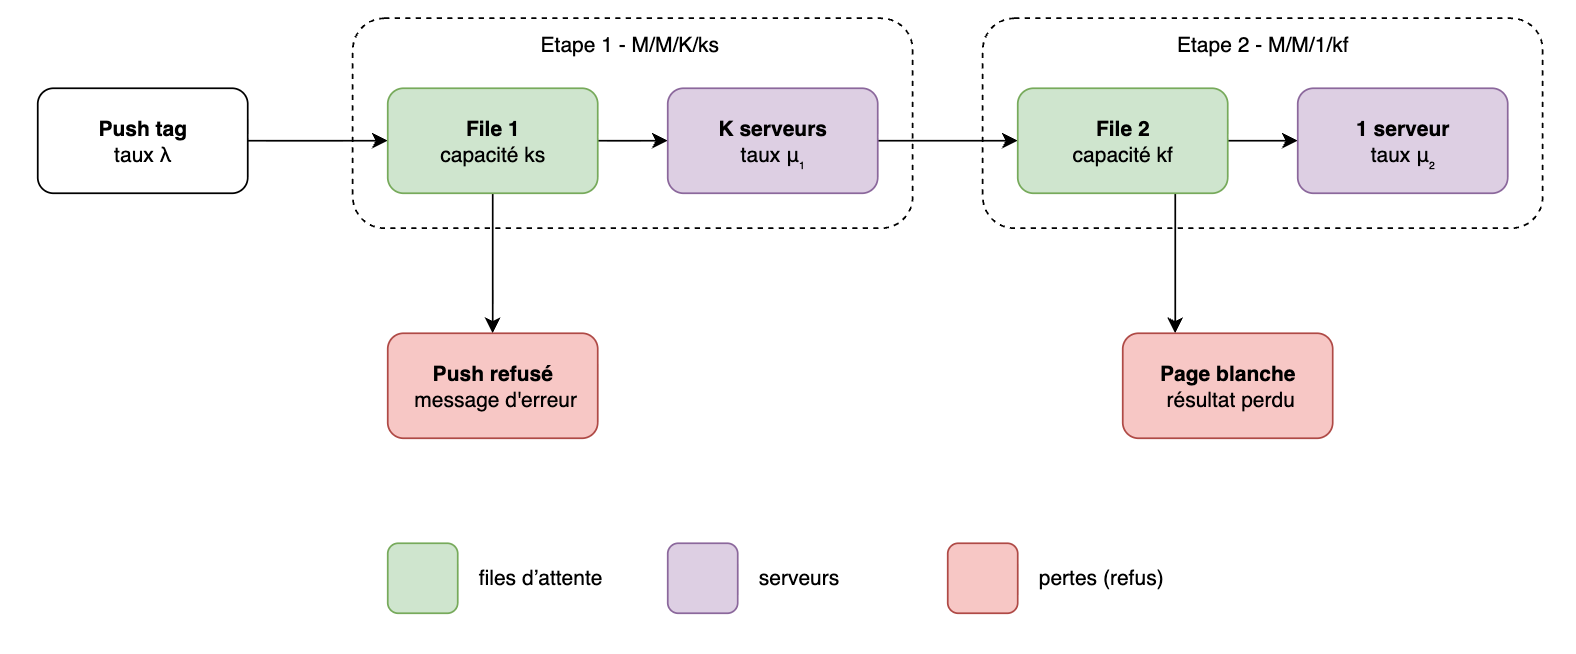

In [1]:
from IPython.display import Image
Image("../images/2.png")

# Simulations

### Simulation 1 : régime stable

**Question :** à charge normale, les refus simulés correspondent-ils à la théorie ?

On reprend les paramètres du Notebook 1 : λ = 0,5, μ1 = 1/60, K = 40, μ2 = 2, soit ρ1 = 0,75 et ρ2 ≈ 0,25. On fait varier ks (kf = 5 fixé), puis kf (ks = 45 fixé).

Chaque point simulé est une moyenne sur B = 30 réplications de 20 000 pushs, avec son intervalle de confiance à 95 %. On le compare à deux références :
- **exact** : la loi stationnaire de la chaîne de Markov du système complet, sans hypothèse sur le flux entre les deux files ;
- **approximation poissonnienne** : la file 2 vue comme une M/M/1/kf alimentée par un Poisson de taux λ(1 − P1), comme dans les hypothèses.

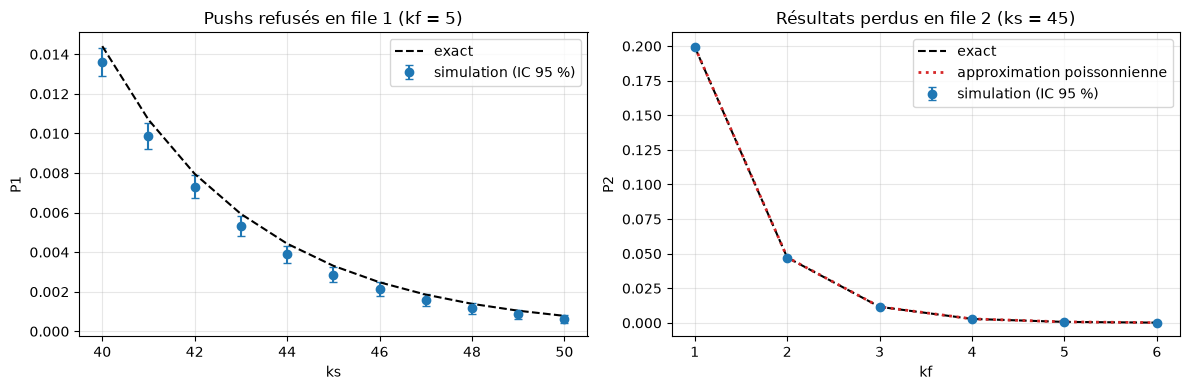

In [ ]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import WaterfallSimulation2
from Utils import Utils

LAM, MU1, K, MU2 = 0.5, 1/60, 40, 2.0
KS_FIX, KF_FIX = 45, 5
B, N_AGENTS = 30, 20_000
ks_values, kf_values = range(K, K + 11), range(1, 7)


def simulate(ks, kf, file):
    """Moyenne et demi-largeur de l'IC à 95 % du taux de refus de la file donnée, sur B réplications."""
    rates = []
    for b in range(B):               # seed différent à chaque réplication
        s = WaterfallSimulation2.waterfall_simulation_2(
            LAM, MU1, K, MU2, ks, kf, np.random.default_rng(10 + b), test_z=N_AGENTS)
        s.run()
        rates.append(s.refusal_rate(file))
    return np.mean(rates), 1.96 * np.std(rates, ddof=1) / np.sqrt(B)


p1_sim = np.array([simulate(ks, KF_FIX, 1) for ks in ks_values])
p1_exact = [Utils.tandem_blocking_exact(LAM, MU1, K, ks, MU2, KF_FIX)[0] for ks in ks_values]

p2_sim = np.array([simulate(KS_FIX, kf, 2) for kf in kf_values])
p2_exact, p2_approx = [], []
for kf in kf_values:
    p1, p2 = Utils.tandem_blocking_exact(LAM, MU1, K, KS_FIX, MU2, kf)
    p2_exact.append(p2)
    p2_approx.append(Utils.mmkn_blocking(LAM * (1 - p1), MU2, 1, kf))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].errorbar(ks_values, p1_sim[:, 0], yerr=p1_sim[:, 1], fmt='o', capsize=3, label='simulation (IC 95 %)')
axes[0].plot(ks_values, p1_exact, 'k--', label='exact')
axes[0].set(xlabel='ks', ylabel='P1', title=f'Pushs refusés en file 1 (kf = {KF_FIX})')

axes[1].errorbar(kf_values, p2_sim[:, 0], yerr=p2_sim[:, 1], fmt='o', capsize=3, label='simulation (IC 95 %)')
axes[1].plot(kf_values, p2_exact, 'k--', label='exact')
axes[1].plot(kf_values, p2_approx, ':', color='tab:red', lw=2, label='approximation poissonnienne')
axes[1].set(xlabel='kf', ylabel='P2', title=f'Résultats perdus en file 2 (ks = {KS_FIX})')

for ax in axes:
    ax.grid(alpha=.3)
    ax.legend()
plt.tight_layout()
plt.show()

**Lecture :**

- **File 1 :** la simulation retrouve la valeur exacte, aux intervalles de confiance près. Sans place d'attente (ks = K, Erlang-B), 1,4 % des pushs sont refusés. 10 places d'attente suffisent à descendre sous 0,1 %.
- **File 2 :** avec kf = 1, 20 % des résultats sont perdus, alors que le serveur n'est occupé qu'un quart du temps (ρ2 ≈ 0,25). Il suffit de quelques places : 1,2 % de pertes pour kf = 3, moins de 0,1 % pour kf = 5.
- **Approximation poissonnienne :** elle se confond avec l'exact. Comme presque aucun push n'est refusé, le flux qui sort de la file 1 reste quasi poissonnien.

À charge normale, le modèle est donc validé, et quelques places d'attente rendent les refus négligeables. Ce cas sert de référence pour la suite.

# Conclusion